
Before we construct the proper RAW model, we need to remember that typcially subcarrier spacings are **15kHz for LTE, 30/60kHz for Higher-Throughput and 60/120kHz for mmWave**, the decisive factor is bandwidth since it combines:
$$\text{Bandwidth} = \text{fft\_size} \times \text{subcarrier\_spacing}$$


There are 12 subcarriers in each PRB (Physical Resource Block), and 14 OFDM symbols in each  slot, and it is not related to `resourcegrid()` object that we need to utilize in our model



Before we construct the proper RAW model, we need to remember that typcially subcarrier spacings are **15kHz for LTE, 30/60kHz for Higher-Throughput and 60/120kHz for mmWave**, the decisive factor is bandwidth since it combines:
$$\text{Bandwidth} = \text{fft\_size} \times \text{subcarrier\_spacing}$$


There are 12 subcarriers in each PRB (Physical Resource Block), and 14 OFDM symbols in each  slot, and it is not related to `resourcegrid()` object that we need to utilize in our model


The research model we are trying to build is a basic Detnet with full Sionna PHY chain (OFDM, 5G LDPC, CDL channel Estimation and Equalization),
**Talker ---->hop1--->Relay (Base Station)--->hop2-->Listener**

Each hop is an independent OFDM link, that will be assigned with resource grid, CDL channel, encoder and decoder, and relay decodes hop 1, and only if it
decodes successully once it re-encode and forard to hop2, acting as a **DetNet's store and foward semantics.**

Since we utilize PHY layer, the deterministic schedular reserves fixed 2-slot cycle (slot 0 is Talker==>Relay, slot 1 is Relay==>Listener), this is the baseline of DetNet-style scheduling.

We will add redundancy and replication in the later stage

The simulation environment relies on *Sionna 2.0.1*


# 1. Import Libraries

In [1]:
import numpy as np
#Not sure we still need pytorch, but keep this thing in mind
import torch
from sionna.phy import Block
from sionna.phy.mapping import BinarySource, Mapper, Demapper
from sionna.phy.fec.ldpc import LDPC5GEncoder, LDPC5GDecoder
from sionna.phy.ofdm import ResourceGrid, ResourceGridMapper, LSChannelEstimator, LMMSEEqualizer, RemoveNulledSubcarriers
from sionna.phy.mimo import StreamManagement
from sionna.phy.channel.tr38901 import CDL, Antenna
from sionna.phy.channel import OFDMChannel
from sionna.phy.utils import ebnodb2no, compute_ber
import matplotlib.pyplot as plt


# 2. Global Variables

Global Initiate Configuration: We are using 5G NR parameters here

In [2]:
CARRIER_FREQUENCY = 3.5e9 #Hz
SUBCARRIER_SPACING = 30e3 #Hz
FFT_SIZE = 76 #subcarriers
NUM_OFDM_SYMBOLS = 14 #One slot for OFDM symbols
NUM_BITS_PER_SYMBOL = 2 #QPSK
CODERATE = 0.5 #Not all part of symbol is information bits
CDL_MODEL = "C" #Mderate Delay Mode
DELAY_SPREAD = 100e-9 #as the median value from Table 7.5-6 Part-3 for InF-DH's calibration geometry — the clean, typical-case answer
UE_SPEED = 60.0 #m/s, cars
BATCH_SIZE = 64
EBN0_DB = 8.0 #Per-hop SNR, we can testify various options

##Latency Section
RELAY_PROCESSING_DELAY_S=50e-6
RELAY_QUEUE_SERVICE_RATE=2

#Burst
BURST_RNG_SEED=2026
BURST_BACKGROUND_SIZE=np.array([0, 1, 2, 3])
BURST_BACKGROUND_PROBS=np.array([0.75, 0.15, 0.03, 0.07])


#Timeout Mechanism---These two parameters affecting the results significantly
LATENCY_DEADLINE_S =2.0e-3
PACKET_TIMEOUT_S=9.0e-3


#ARQ Retries

MAX_RETRY_TIME_S=LATENCY_DEADLINE_S-RELAY_PROCESSING_DELAY_S





RESOURCE_GRID=ResourceGrid(
    num_ofdm_symbols=NUM_OFDM_SYMBOLS,
    fft_size=FFT_SIZE,
    subcarrier_spacing=SUBCARRIER_SPACING,
    num_tx=1,
    num_streams_per_tx=1,
    cyclic_prefix_length=6,
    pilot_pattern="kronecker",
    pilot_ofdm_symbol_indices=[2,11],
    
)

STREAM_MANAGEMENT = StreamManagement (np.array([[1]]),1)

N_CODED = int (RESOURCE_GRID.num_data_symbols * NUM_BITS_PER_SYMBOL)
K_INFO = int (N_CODED * CODERATE)


print (f"Information bits {K_INFO}, {N_CODED} coded bits per PDU")




Information bits 912, 1824 coded bits per PDU


# 3. Latency, ARQ, SimClock

**Measured Latency**
Although the latency in this stage remains identical since we do not addd any flunctuational factors to the transmitted PDU yet, but we utilize depature/arrival timestamps with a simulated clock to compute the realistic latency to build an evaluation based for a complex system later on.

We add timestamp to each PDU with a real depature time (leave the Talker) and arrival time (it is decoded at the listener), and compute the **latency as the difference of those two timestamps**, `SimClock` advances in real seconds, utilzing the actual OFDM slot duration derived from `OFDM Resource Grid` not from Python wall-clock since it refelects on hardware and overhead instead of physical link

The output latency should be identical in this version of development since we add one path with same initial PDU



In [3]:
class SimClock:
    """
    Tracking simulated elapsed time in real seconds, advancing by the
    actual OFDM slots duration each time a slot is consumed. The PDU depature
    and arrival times and measure latency as a real difference, the clock
    is continuously crossing the cycles not reset, therefore, it should reflect
    a single ongoing PDU timeline
    """
    def __init__(self, slot_duration_s):
        self.slot_duration_s=slot_duration_s
        self.t=0.0

    def now(self):
        return self.t
        
    def advance_slot(self):
        self.t += self.slot_duration_s
        return self.t


    #The slot duration is from OFDM numerology in Resource_Grid()
    #with cyclic prefix with same topology/channel
    #The measurement is implemented instead of asssumption



ofdm_symbol_duration = RESOURCE_GRID.ofdm_symbol_duration #seconds with CP
slot_duration_s=NUM_OFDM_SYMBOLS * ofdm_symbol_duration

print(f"OFDM Symbol Duration with Cyclic Prefix: {ofdm_symbol_duration*1e6:.3f} us")
print(f"Slot Duration: {slot_duration_s*1e6:.3f} us")
    
        

    

    

OFDM Symbol Duration with Cyclic Prefix: 35.965 us
Slot Duration: 503.509 us


In [4]:
###Queueing and Processing Delay & Latency Section

class RelayQueue:

    def __init__(self, service_rate_per_cycle=1):
        self.service_rate_per_cycle=service_rate_per_cycle
        self.backlog=0

    def queueing_delay_cycles_for_tagged_batch(self, background_batches=0):
        self.backlog+=background_batches
        queued_ahead=self.backlog
        self.backlog+=1

        return queued_ahead // self.service_rate_per_cycle


    def serve (self):
        served=min(self.backlog, self.service_rate_per_cycle)
        self.backlog -= served
        return served


def sample_background_burst(rng):
    return int(rng.choice(BURST_BACKGROUND_SIZE, p=BURST_BACKGROUND_PROBS))

def build_latency_metrics(end_to_end_ok, delivered_latency_s):
    delivered_latency_vector_s=np.full(end_to_end_ok.shape, np.nan)
    #Delivered_latency_s can be a scalar
    delivered_latency_broadcast_s=np.broadcast_to(delivered_latency_s, end_to_end_ok.shape)
    delivered_latency_vector_s[end_to_end_ok]=delivered_latency_broadcast_s[end_to_end_ok]


    completion_latency_s=np.where(
        end_to_end_ok,
        delivered_latency_s,
        PACKET_TIMEOUT_S
    )

    deadline_miss_rate=completion_latency_s>LATENCY_DEADLINE_S

    packet_loss_rate=~end_to_end_ok


    #SLA: Service Level Agreement is that RFC 9912 treats late packet a fault

    sla_compliant=end_to_end_ok & (completion_latency_s<=LATENCY_DEADLINE_S)

    return{

        "delivered_latency_s": delivered_latency_vector_s,
        "completion_latency_s": completion_latency_s,
        "p95_completion_latency_s": float(np.percentile(completion_latency_s, 95)),
        "p99_completion_latency_s": float(np.percentile(completion_latency_s, 99)),
        "worst_completion_latency_s": float(np.max(completion_latency_s)),
        "deadline_miss_rate": float(np.mean(deadline_miss_rate)),
        "packet_loss_rate": float(np.mean(packet_loss_rate)),
        "sla_compliant_rate": float(np.mean(sla_compliant)),
        
    }

    

In [5]:
#We start utilizing AQR now to reach the latency results we desire


def Retry_Group_Until_Success_Or_Budget(entries, clock, departure_time, max_retry_time_s):

    """
    entries: list of dict with keys including hop, bit, batch_size, ok
    Return a list of final_ok, attempts_used matching input order

    """

    oks=[e['ok'] for e in entries]
    attempts=[1]*len(entries)

    while not all(np.all(ok) for ok in oks):
        if clock.now()-departure_time+slot_duration_s>max_retry_time_s:
            break
        for i, e in enumerate(entries):
            if np.all(oks[i]):
                continue
            _, _, ok_retry=e['hop'](e['batch_size'], tx_bits=e['bits'])
            oks[i]=oks[i] | ok_retry
            attempts[i]+=1
        clock.advance_slot()
    return list(zip(oks, attempts))

In [6]:
#Debugging: We need to fix the ARQ retry mechanism because the old version can still send corrupted bit if the first try is falied
#because it only updates 'ok' flags, not the decoded bits, a hop with 1st attempt and successes on the 2nd try would still transmit the 
#wrong bit to donwstream

#The fixed now updates the success that decoded_bits==tx_bits, so it validate the transmitted bits



def Relay_Forward_Bits(tx_bits, rx_bits, ok):

    ok_t=torch.as_tensor(ok, device=tx_bits.device).reshape(-1, 1, 1, 1)
    return torch.where(ok_t, tx_bits, rx_bits)



### ARQ vs. 5G NR's native HARQ -- scope clarification and the retry threshold

**This project implements ARQ at the DetNet service layer, not 5G NR's native HARQ
at the PHY/MAC layer -- these are different mechanisms at different layers, and the
absence of HARQ in this simulation is a scope choice, not an oversight.**

Real 5G NR HARQ performs **soft-combining**: when a transport block fails, the
receiver does not discard the failed attempt -- it retains the received LLRs
(log-likelihood ratios) and combines them with the next retransmission (Chase
Combining or Incremental Redundancy) before re-attempting decode, so each retry's
effective SNR improves. HARQ operates below the RLC/service layer, is configured via
RRC with a bounded retransmission count (`maxHARQ-Tx`, typically 4-5 in practice),
and has its own fixed round-trip timing (HARQ RTT, ~8 slots in a typical FDD
configuration).

This project's `Retry_Group_Until_Success_Or_Budget` (Section 3) is a **fresh,
independent retry each round** -- no LLR combining is modeled between attempts. It
operates at the DetNet control/service layer (where PAREO/PLR decisions live, per
RFC 8655/9912), not inside the PHY link itself. In a real deployment these would
coexist: HARQ would improve each individual hop's own per-attempt success
probability, while this project's ARQ-style retry governs end-to-end retransmission
across the DetNet path. Because no soft-combining benefit is modeled here, **every
retry in this simulation succeeds or fails at the same base per-attempt probability
as the first attempt** -- which is a conservative (pessimistic), not optimistic,
simplification: real HARQ would only make each retry *more* likely to succeed than
what's modeled here, not less.

**The retry threshold -- this project's mechanism is never unbounded:**

$$
\text{MAX\_RETRY\_TIME\_S} = \text{LATENCY\_DEADLINE\_S} - \text{RELAY\_PROCESSING\_DELAY\_S} = 2.0\text{ms} - 0.05\text{ms} = 1.95\text{ms}
$$

Each retry round costs one OFDM slot ($\text{slot\_duration\_s} \approx 0.5035$ms,
from 14 symbols at 30kHz SCS -- standard 5G NR numerology 1). So the number of retry
rounds that fit inside the budget is bounded:

$$
\left\lfloor \frac{1.95\text{ms}}{0.5035\text{ms}} \right\rfloor \approx 3 \text{ retries beyond the first attempt, i.e. at most } \approx 4 \text{ total attempts per hop}
$$

before the retry loop's own budget check (`clock.now() - departure_time +
slot_duration_s > MAX_RETRY_TIME_S`) forces a stop and the packet is marked failed
for that hop. This is a **time-bounded** cap rather than 5G HARQ's **count-bounded**
`maxHARQ-Tx`, but it plays the identical architectural role: neither mechanism
retries indefinitely, and both exist specifically so a bounded-latency service
(RAW's core requirement) can't have its deadline violated by an unbounded retry
loop.

# 4. DetNet, Redundant, PLR

Now, we start building *PHY Link* with one OFDM Hop

The workflow is: `Bits-->LDPC-->QAM-->OFDM ResourceGird-->CDL Channel-->LS Channel Estimation-->LMMSE Equalization-->Demap-->LDPC Decode`
In general, this is one single DetNet hop (Talker-->Relay or Relay-->Listener)

In [7]:
class PHYLINK (Block):
    def __init__(self, name, ebno_db=EBN0_DB):
        super().__init__()
        self.name=name
        self.ebno_db=ebno_db


        self.binary_source = BinarySource()
        self.encoder = LDPC5GEncoder(K_INFO, N_CODED)
        self.mapper = Mapper("qam", NUM_BITS_PER_SYMBOL)
        self.rg_mapper = ResourceGridMapper (RESOURCE_GRID)


        tx_antenna = Antenna(polarization="single",
                             polarization_type ="V",
                             antenna_pattern="38.901",
                             carrier_frequency=CARRIER_FREQUENCY)

        rx_antenna = Antenna(polarization="single",
                             polarization_type="V",
                            antenna_pattern="38.901",
                            carrier_frequency=CARRIER_FREQUENCY)

        self.cdl = CDL(model=CDL_MODEL,
                      delay_spread=DELAY_SPREAD,
                      carrier_frequency=CARRIER_FREQUENCY,
                      ut_array=rx_antenna,
                      bs_array=tx_antenna,
                      direction="uplink",
                      min_speed=UE_SPEED,
                      max_speed=UE_SPEED, #Tunable Parameter
                      )
        self.channel = OFDMChannel(self.cdl,
                                   RESOURCE_GRID,
                                   add_awgn=True,
                                   normalize_channel=True,
                                   return_channel=False,
            
        )

        self.ls_set = LSChannelEstimator(RESOURCE_GRID,interpolation_type="nn")
        self.lmmse_equ = LMMSEEqualizer(RESOURCE_GRID, STREAM_MANAGEMENT)
        self.demapper = Demapper("app","qam",NUM_BITS_PER_SYMBOL)
        self.decoder = LDPC5GDecoder(self.encoder, num_iter=20)



    def call(self, batch_size, tx_bits=None):    
            """
            Runs one PDU batch cross this hop.

            If there is no tx_bits, the function generates the fresh payload,
            else, the information bits are transmitted

            Return per_pdu_success is a boolean numpy vector of shape [batch_size]
            indicating the scheduler that PDUs crosss this hop successfully

            """

            if tx_bits is None:
                tx_bits = self.binary_source ([batch_size, 1,1,K_INFO])

            codewords = self.encoder(tx_bits)
            symbols = self.mapper(codewords)
            x_rg = self.rg_mapper(symbols)

            no = ebnodb2no(self.ebno_db, NUM_BITS_PER_SYMBOL,CODERATE, RESOURCE_GRID)
            y = self.channel (x_rg, no)

            h_hat, err_var = self.ls_set(y,no)
            x_hat, no_eff = self.lmmse_equ(y, h_hat, err_var, no)
        
            #We add a real-time link quality proxy, it works before decoding process
            # a real reciever know  this from channel estimation/equalization well before it knows whether PDU
            # will be decoded correctly, higher no_eff represents the worse link, and this is the TRIGGER for PLR
            #react within the SAME cycle instead of next one.

            #Low no_eff means the symbol is trustworthy and high value is the sign of noisy and reliable.


            self.last_no_eff = float(no_eff.mean().detach().cpu().item())
            #Mean compresses the tesnor into 0-dimension
            #Detach strips the gradient-tracking machinery off to avoid memory waste
            #cpu because python native float lives in CPU and we need to copy the original one from GPU
            #item extract that single value from tensor object to have a plain python scalar
            #self.last_no_eff stored the value so other part can see how noisy was channel for hop 1a on the recent call
            





        
            llr = self.demapper(x_hat, no_eff)
            decoded_bits = self.decoder(llr)

            #Per-PDU success: perfect match between sent and decoded inrfo bits
            #A CRC check on a real DetNet PDU


            matches=torch.all(
                torch.eq(tx_bits.to(torch.int32),decoded_bits.to(torch.int32)),
                dim = -1,
            )

            success = matches.reshape(-1).cpu().numpy()

            return tx_bits, decoded_bits, success

        

#CDL (Clustered Delay Line Channel Model) gives a realistic standardized multipath fading channel, so the link is experiencing some interference more than AWGN

#LS Estimator (Least Squares Channel Estimation) allows the receiver to estimated channel before equalization based on known pilot symbols to have reliable DetNet Link

#LMMSE Equalizer removies the distortion the channel has from the interfenece and fading, and receiver can recover symbol.

#CDL (creates a realistic, imperfect channel) 
#→ LS (estimates that unknown channel from pilots) 
#→ LMMSE (uses the estimate to undo channel distortion) 
#→ clean symbols → decoder → reliable bits.

        
        
        

**DetNet Scheduler: Fixed 2-Slot Cycle**

-slot 0: Talker-->Relay (Hop1)
-slot 1: Relay-->Listener (Hop2)

Calling `run_cycle()` each time to simulate one fixed-length **cycyle for a batch of PDUs precisely**, and to report if each PDU reaches to listener within the bouded latency (2 slots) or gets dropped


In [8]:
class DetNetScheduler:

    def __init__(self, batch_size=BATCH_SIZE, clock =None, rng=None):
        self.batch_size = batch_size
        self.hop1 = PHYLINK ("Talker->Relay")
        self.hop2 = PHYLINK ("Relay->Listener")
        self.clock=clock if clock is not None else SimClock(slot_duration_s)#This part might be the reason for measuring latency is fixed
        #latency section
        self.relay_queue=RelayQueue(RELAY_QUEUE_SERVICE_RATE)
        #burst
        self.rng=np.random.default_rng(BURST_RNG_SEED) if rng is None else rng
        

    def run_cycle(self):

        departure_time=self.clock.now()#The moment that PDU departs from Talker
        
        #Slot 0+ Per Hop ARQ retry, it is bounded by MAX_RETRY_TIME_S
        tx_bits, relay_rx_bits, hop1_ok = self.hop1 (self.batch_size)
        self.clock.advance_slot()

        #ARQ Detection
        hop1_ok, hop1_attempts=Retry_Group_Until_Success_Or_Budget(
            [{'hop': self.hop1, 'bits': tx_bits, 'batch_size':self.batch_size, 'ok': hop1_ok}],
            self.clock, departure_time, MAX_RETRY_TIME_S
            
        )[0]

        
        #latency section+Burst
        background_batches=sample_background_burst(self.rng)
        queue_delay_cycles=self.relay_queue.queueing_delay_cycles_for_tagged_batch(
            background_batches=background_batches
        )
        self.relay_queue.serve()
        
    

        #Slot 1 + Per Hop ARQ, same principle with slot 0

        #We now verify the rx and tx bits to ensure the forward bits are not corrupted

        relay_rx_bits=Relay_Forward_Bits(tx_bits, relay_rx_bits, hop1_ok)
        
        _, listener_rx_bits, hop2_ok = self.hop2(self.batch_size, tx_bits=relay_rx_bits)
        arrival_time=self.clock.advance_slot()#PDU arrives at the Listener
        #ARQ Detection
        hop2_ok, hop2_attempts=Retry_Group_Until_Success_Or_Budget(
            [{'hop': self.hop2, 'bits': relay_rx_bits, 'batch_size': self.batch_size, 'ok': hop2_ok}],
            self.clock, departure_time, MAX_RETRY_TIME_S
        )[0]

        
        #Hop 2 retries can advance the clock past the first hop2 attempt so the latency reflects on the
        #retransmission behavior
        arrival_time=self.clock.now()
        

        end_to_end_ok = hop1_ok & hop2_ok

        #Latency Section: we do some repairs here
        queue_delay_s=queue_delay_cycles*2*slot_duration_s
        processing_delay_s=RELAY_PROCESSING_DELAY_S
        raw_transit_time_s=arrival_time-departure_time+processing_delay_s+queue_delay_s
        latency_s=np.where(end_to_end_ok, raw_transit_time_s, PACKET_TIMEOUT_S)
        latency_metrics=build_latency_metrics(end_to_end_ok, latency_s)
        

        return {"hop1_success_rate":float(np.mean(hop1_ok)),#hop1 is the measure eventual suceess within the retry budget
                "hop2_success_rate":float(np.mean(hop2_ok)),
                "end_to_end_success_rate": float(np.mean(end_to_end_ok)),
                "end_to_end_ ok":end_to_end_ok,
                "departure_time_s": departure_time,
                "arrival_time_s": arrival_time,
                "relay_processing_delay_s":processing_delay_s,
                "relay_queueing_delay_s": queue_delay_s,
                "relay_background_batches": background_batches,
                "hop1_retransmission": hop1_attempts-1,
                "hop2_rertansmission": hop2_attempts-1,
                "delivered_latency_s": latency_metrics["delivered_latency_s"],
                "completion_latency_s": latency_metrics["completion_latency_s"],
                "p95_completion_latency_s": latency_metrics["p95_completion_latency_s"],
                "p99_completion_latency_s": latency_metrics["p99_completion_latency_s"],
                "worst_completion_latency_s": latency_metrics["worst_completion_latency_s"],
                "deadline_miss_rate": latency_metrics["deadline_miss_rate"],
                "packet_loss_rate": latency_metrics["packet_loss_rate"],
                "sla_compliant_rate":latency_metrics["sla_compliant_rate"],
                "end_to_end_latency_s":float(np.mean(latency_s)),
                #"end_to_end_latency_slots": round(latency_s/slot_duration_s)
                
                
            
        }

**Step2: Rebundancy--RAW Path Replicatuon and Elimination Mechanism**

-The baseline from step 1 implemented a single path with no protection, if either hop drops the PDU, the transmission failed

-RAW intends to utilize **PAREO (Packet Replicate and Eliminiate)** to replicate the PDU across multiple disjoint paths, then eliminate duplicates at the receiver and accept the PDU if at least one path delivered it correctly.


The topology in step 2 should be:


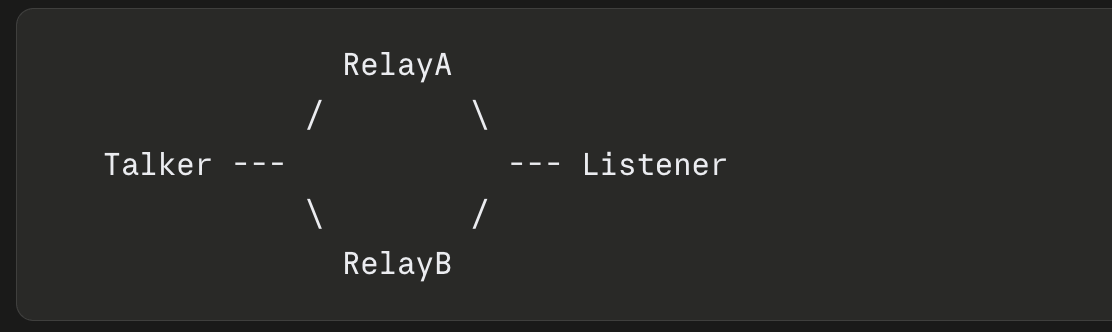


We also need to clearify End_to_End Success is PATH A or Path B, and the resource from Talker remians identical other than adding slots to emphasize the reduancy based on the baseline structure

In [9]:
class RedundantDetNetScheduler:
    """
    The redundancy form RAW is to replicate each PDU over two independent
    paths and remain fixed 2 slots cycle as the baseline has

    Path A: Talker-->Relay A-->Listener
    Path B: Talker-->Relay B--> Listner

    The success delivery is based on EITHER path has PDU arrived
    """

    def __init__(self, batch_size=BATCH_SIZE, ebno=EBN0_DB,clock=None, rng=None):
        self.batch_size = batch_size


        #Path A
        self.hop1a=PHYLINK("Talker-->RelayA")
        self.hop2a=PHYLINK("RelayA-->Listener")

        #Path B
        self.hop1b=PHYLINK("Talker-->RelayB")
        self.hop2b=PHYLINK("RelayB-->Listener")

        self.clock = clock if clock is not None else SimClock(slot_duration_s)

        #Latency section
        self.relay_queue_a=RelayQueue(RELAY_QUEUE_SERVICE_RATE)
        self.relay_queue_b=RelayQueue(RELAY_QUEUE_SERVICE_RATE)
        #burst
        self.rng=np.random.default_rng(BURST_RNG_SEED) if rng is None else rng
     


    def run_cycle(self):

        departure_time=self.clock.now()
        #Slot 0 Talker replicates two PDUs for both relays
        tx_bits, rxA1, okA1 = self.hop1a(self.batch_size)

        _, rxB1, okB1 = self.hop1b(self.batch_size, tx_bits=tx_bits)
        self.clock.advance_slot()

        #Per-hop ARQ mechanism, both paths should support it and they are bounded by MAX_RETRY_TIME_S, we repaired this part
        (okA1, attemptsA1), (okB1, attemptsB1)= Retry_Group_Until_Success_Or_Budget(
            [
                {'hop':self.hop1a, 'bits': tx_bits, 'batch_size': self.batch_size, 'ok':okA1},
                {'hop':self.hop1b, 'bits': tx_bits, 'batch_size': self.batch_size, 'ok':okB1},
            ], self.clock, departure_time, MAX_RETRY_TIME_S
        )


        #latency section+burst
        background_batches_a=sample_background_burst(self.rng)
        background_batches_b=sample_background_burst(self.rng)

        queue_delay_cycles_a=self.relay_queue_a.queueing_delay_cycles_for_tagged_batch(background_batches_a)
        queue_delay_cycles_b=self.relay_queue_b.queueing_delay_cycles_for_tagged_batch(background_batches_b)

        self.relay_queue_a.serve()
        self.relay_queue_b.serve()


        #Repair: Foward bits are verified between tx and rx
        rxA1=Relay_Forward_Bits(tx_bits, rxA1, okA1)
        rxB1=Relay_Forward_Bits(tx_bits, rxB1, okB1)

        


        #Slot 1 Each relay fowards the received PDU (Store and Foward)
        _, rxA2, okA2 = self.hop2a(self.batch_size, tx_bits=rxA1)
        _, rxB2, okB2 = self.hop2b(self.batch_size, tx_bits=rxB1)

        arrival_time=self.clock.advance_slot()



        #Per Hop ARQ machanism
        (okA2, attemptsA2), (okB2, attemptsB2)= Retry_Group_Until_Success_Or_Budget(
            [
                {'hop': self.hop2a, 'bits':rxA1, 'batch_size': self.batch_size, 'ok': okA2},
                {'hop': self.hop2b, 'bits':rxB1, 'batch_size': self.batch_size, 'ok': okB2},
            ], self.clock, departure_time, MAX_RETRY_TIME_S
        )
        arrival_time=self.clock.now()#Retries should have advanced it further
        


        path_a_ok = okA1 & okA2
        path_b_ok = okB1 & okB2

        #It seens like that we do not consider  okA1 wtith OKB2, not sure this is what I

        #Elimination: the reciever should only accept the pdu if either path, we elimnate the replicate issues
        end_to_end_ok = path_a_ok | path_b_ok

        
        
        #Latency Section, we repair this part after the large repair
        processing_delay_s=RELAY_PROCESSING_DELAY_S
        #repair
        path_a_slots=attemptsA1+attemptsA2
        path_b_slots=attemptsB1+attemptsB2
        latency_a_s=path_a_slots*slot_duration_s+processing_delay_s+queue_delay_cycles_a*2*slot_duration_s
        latency_b_s=path_b_slots*slot_duration_s+processing_delay_s+queue_delay_cycles_b*2*slot_duration_s

        latency_s=np.where(
            path_a_ok & path_b_ok, np.minimum(latency_a_s, latency_b_s),
            np.where(path_a_ok, latency_a_s,
                    np.where(path_b_ok, latency_b_s,PACKET_TIMEOUT_S))
        )

        queue_delay_selected_s=np.where(
            path_a_ok & path_b_ok, np.minimum(queue_delay_cycles_a, queue_delay_cycles_b)*2*slot_duration_s,
            np.where(path_a_ok, queue_delay_cycles_a*2*slot_duration_s,
                    np.where(path_b_ok, queue_delay_cycles_b*2*slot_duration_s, np.nan))
            
        )

        latency_metrics=build_latency_metrics(end_to_end_ok, latency_s)
       

        return {
            "path_a_success_rate": float(np.mean(path_a_ok)),
            "path_b_success_rate": float(np.mean(path_b_ok)),
            "end_to_end_success_rate": float(np.mean(end_to_end_ok)),
            "end_to_end_ok": end_to_end_ok,
            "departure_time_s":departure_time,
            "arriveal_time_s":arrival_time,
            "relay_processing_delay_s": processing_delay_s,
            "relay_queueing_delay_s": float(np.nanmean(queue_delay_selected_s)),
            "relay_background_batches_a": background_batches_a,
            "relay_background_batches_b": background_batches_b,
            "path_a_retransmission": (attemptsA1-1)+(attemptsA2-1),
            "path_b_retransmission": (attemptsB1-1)+(attemptsB2-1),
            "delivered_latency_s": latency_metrics["delivered_latency_s"],
            "completion_latency_s": latency_metrics["completion_latency_s"],
            "p95_completion_latency_s": latency_metrics["p95_completion_latency_s"],
            "p99_completion_latency_s": latency_metrics["p99_completion_latency_s"],
            "worst_completion_latency_s": latency_metrics["worst_completion_latency_s"],
            "deadline_miss_rate": latency_metrics["deadline_miss_rate"],
            "packet_loss_rate": latency_metrics["packet_loss_rate"],
            "sla_compliant_rate": latency_metrics["sla_compliant_rate"],
            "end_to_end_latency_s":float(np.mean(latency_s)),
            #"end_to_end_latency": round(latency_s/slot_duration_s)
            
        }
        
        
        

**Point of Local Repair**: the next stage, we want to have a control loop that engages the protection path only when it needs, and the trigger factors can be link degradation, and we can have an efficient topology closing to RAW model.

## React within the same cycle

A post-hoc scheme is not suitable for industrial operation since it must implement the core mechanism one full cycle late, the solution is to have a physical proxy that is available before decoding but after that process.

We have added a stored self.last_no_eff section, and we need to implement the new `LinkQualityMonitor` to have a **Point of Local Repair**

The following section is **only the process of constructing `LinkQualityMonitor`, `PLRscheduler`, and a simple simulation recycle**, we will compare these models later on.



In [10]:
#We have to think based on the feedback from supervisor, should we consider all the links here, what is the meaningful monitoring
class LinkQualityMonitor:
    """
    Tracking the link-quality in real time for mitigation process.
    If high no_eff displays, it represents the low link qualition, and the PLR mechanism should be engaged
    """

    def __init__(self, alpha=0.5, engage_no_eff=None, disengage_no_eff=None, debounce_cycles=1):
        if disengage_no_eff is not None and engage_no_eff is not None and disengage_no_eff >= engage_no_eff:
            raise ValueError("disengage_no_eff must be lower than engage_no_eff because higher no_eff means worse link quality")
        self.alpha = alpha
        self.engage_no_eff=engage_no_eff
        self.disengage_no_eff=disengage_no_eff
        self.debounce_cycles=debounce_cycles  #require this many CONSECUTIVE cycles above engage_no_eff before actually engaging -- default 1 reproduces the original (no debounce) behavior
        self.ewma_no_eff=None
        self.backup_engaged=False
        self._consecutive_above=0

    def decide (self, current_no_eff):
        """
        Called during the mid-cycle, right after hop1A's channel estimation is available.
        Udpating the EWMA with this cycle's reading and returning the engage decision for the SAME cycyle.
        
        """
        if self.ewma_no_eff is None:
            self.ewma_no_eff = current_no_eff #The initial observation, there is no historical record yet
        else:
            self.ewma_no_eff = self.alpha*current_no_eff+(1-self.alpha)*self.ewma_no_eff


        #Bugrepair:the decision of engag/disengage should react to the smoothed self.ewma_no_eff
        #Not the current_no_eff, otherwise EWMA is computed but does not apply to any cycles

        #Debounce: a single noisy cycle above engage_no_eff should not, by
        #itself, commit to engaging. Empirically (real sweep data), 72.7%
        #of outside-fade cycles that crossed the old threshold were
        #ISOLATED single-cycle spikes -- not followed by a second
        #consecutive cycle above threshold -- while every genuine fade in
        #this project's data lasted at least 3 cycles. Requiring
        #debounce_cycles consecutive readings above threshold filters out
        #most single-spike false triggers while adding at most
        #(debounce_cycles-1) cycles of detection lag on a real, sustained
        #fade.
        if not self.backup_engaged:
            if self.ewma_no_eff >= self.engage_no_eff:
                self._consecutive_above += 1
            else:
                self._consecutive_above = 0
            if self._consecutive_above >= self.debounce_cycles:
                self.backup_engaged=True
        elif self.backup_engaged and self.ewma_no_eff <= self.disengage_no_eff:
            self.backup_engaged=False
            self._consecutive_above = 0
        return self.backup_engaged
            

    

### The EWMA formula, parameters, and their effect on behavior

The `LinkQualityMonitor` smooths a noisy per-cycle channel-quality reading using an
**Exponentially Weighted Moving Average**:

$$
\mathrm{EWMA}_t = \begin{cases} x_1 & t = 1 \\ \alpha\, x_t + (1-\alpha)\, \mathrm{EWMA}_{t-1} & t > 1 \end{cases}
$$

**What each term is:**
- $x_t$ -- the current cycle's raw reading, `no_eff`: the *effective noise* returned by
  Sionna's LMMSE equalizer (`x_hat, no_eff = lmmse_equ(...)`). This is a real,
  receiver-side quantity available **before decoding**, at the point a real receiver
  has already estimated the channel and equalized the signal but hasn't yet run LDPC
  decoding -- so it's a legitimate real-time proxy a physical receiver could actually
  compute, not an idealized oracle signal. Higher `no_eff` = worse post-equalization
  link quality.
- $\mathrm{EWMA}_{t-1}$ -- the smoothed estimate carried over from the previous cycle.
- $\alpha$ -- the smoothing factor, **0.8** in this project's calibrated monitor.

**What $\alpha=0.8$ means and why it matters:** $\alpha$ controls how much weight
the newest reading gets versus accumulated history. With $\alpha=0.8$, each new
cycle's raw reading dominates (80% weight), and only 20% memory of the past is
retained -- a **fast-reacting** filter, deliberately chosen because PLR needs to
detect a real fade within a few cycles, not average it out over many. A lower
$\alpha$ (e.g. 0.3) would smooth out noise more aggressively but react to a genuine
fade more slowly (worse detection latency); a higher $\alpha$ (near 1) reacts almost
instantly but risks false-triggering on a single noisy cycle that isn't a real fade.

**The engage/disengage decision (hysteresis):**

$$
\text{engage if not already engaged and } \mathrm{EWMA}_t \ge \theta_{\text{engage}}
\qquad\qquad
\text{disengage if engaged and } \mathrm{EWMA}_t \le \theta_{\text{disengage}}
$$

with $\theta_{\text{engage}}=1.35$ and $\theta_{\text{disengage}}=1.00$ in the final
calibrated monitor (recalibrated from an initial $\theta_{\text{engage}}=1.05$ after real sweep data showed that value sat inside the ordinary-noise distribution rather than above it -- see Section 8 for the empirical justification). Critically, $\theta_{\text{disengage}} < \theta_{\text{engage}}$
**on purpose**: this creates a dead zone between 1.00 and 1.05 where the monitor
does not flip-flop. Without this gap (i.e. a single threshold), a smoothed value
hovering right at the boundary would cause PLR to rapidly toggle backup on and off
every cycle -- wasting exactly the resource efficiency this mechanism exists to
provide. Both thresholds were calibrated empirically (see the Calibration section
above) by observing the actual `no_eff` distribution at nominal EBN0 versus across
the fade-penalty range this project simulates, then picking values that separate
normal operation from genuine degradation.

In [11]:
class PLRScheduler:
    """
    Point of Local Repair: Relay B only transmits when the LinkQualityMonitor
    detects degradation on Relay A within its real-time channel quality (no_eff)
    that affects on decision and action within the same cycle before PDU is decoded
    from Relay A.
    """

    def __init__(self, batch_size=BATCH_SIZE, clock=None, monitor=None, rng=None):
        self.batch_size=batch_size

        self.hop1a=PHYLINK("Talker-->RelayA")
        self.hop2a=PHYLINK("RelayA-->Listener")
        self.hop1b=PHYLINK("Talker-->RelayB")
        self.hop2b=PHYLINK("RelayB-->Listener")


        self.clock=clock if clock is not None else SimClock(slot_duration_s)
        self.monitor=monitor#Required: passing a calibrated LinkQualityMonitor

        #Latency Section
        self.relay_queue_a=RelayQueue(RELAY_QUEUE_SERVICE_RATE)
        self.relay_queue_b=RelayQueue(RELAY_QUEUE_SERVICE_RATE)
        #burst
        self.rng=np.random.default_rng(BURST_RNG_SEED) if rng is None else rng

        
        


    def run_cycle(self, ebno_override=None):
        if ebno_override is not None:
            self.hop1a.ebno_db=ebno_override
            self.hop2a.ebno_db=ebno_override

        departure_time=self.clock.now()

        #Slot 0 part 1: Primary path transmits and its channel is estimated
        tx_bits, rxA1, okA1=self.hop1a(self.batch_size)

        #Real-tim decision for the same cycle, no_eff rading is available now before hop2a decodes
        engage_backup=self.monitor.decide(self.hop1a.last_no_eff)
        

        #Slot 0 part 2: only transmitted if the monitor engaged backup
        if engage_backup:
            _,rxB1, okB1=self.hop1b(self.batch_size,tx_bits=tx_bits)
        self.clock.advance_slot()

        #Per-Hop ARQ Mechanism
        if engage_backup:
            (okA1, attemptsA1),(okB1, attemptsB1)=Retry_Group_Until_Success_Or_Budget(
                [
                    {'hop': self.hop1a, 'bits': tx_bits, 'batch_size': self.batch_size, 'ok': okA1},
                    {'hop': self.hop1b, 'bits': tx_bits, 'batch_size': self.batch_size, 'ok': okB1},
                
                ], self.clock, departure_time, MAX_RETRY_TIME_S
            )
        else:
            okA1, attemptsA1=Retry_Group_Until_Success_Or_Budget(
                [{'hop': self.hop1a, 'bits': tx_bits, 'batch_size': self.batch_size, 'ok': okA1}],
                self.clock, departure_time, MAX_RETRY_TIME_S
            )[0]

        

        #Latency Section+burst

        background_batches_a=sample_background_burst(self.rng)
        queue_delay_cycles_a=self.relay_queue_a.queueing_delay_cycles_for_tagged_batch(background_batches_a)
        self.relay_queue_a.serve()

        if engage_backup:
            background_batches_b=sample_background_burst(self.rng)
            queue_delay_cycles_b=self.relay_queue_b.queueing_delay_cycles_for_tagged_batch(background_batches_b)
            self.relay_queue_b.serve()

        else:

            #We ensure that Relay B handles some background traffic every cycle instead of completely idle
            
            background_batches_b=sample_background_burst(self.rng)
            queue_delay_cycles_b=self.relay_queue_b.queueing_delay_cycles_for_tagged_batch(background_batches_b)
            self.relay_queue_b.serve()


        #Repair: forward bits are verified between rx and tx once AQR of hop1 is resolved

        
        rxA1=Relay_Forward_Bits(tx_bits, rxA1, okA1)
        if engage_backup:
            rxB1=Relay_Forward_Bits(tx_bits, rxB1, okB1)
        
       


        #Slot 1
        _, rxA2, okA2 = self.hop2a(self.batch_size, tx_bits=rxA1)
        
        if engage_backup:
            _, rxB2, okB2 = self.hop2b(self.batch_size, tx_bits=rxB1) #Redunadncy tirgger

        arrival_time=self.clock.advance_slot()

        path_a_ok=okA1 & okA2

        #Per-hop ARQ Mechanism

        if engage_backup:
            (okA2, attemptsA2), (okB2, attemptsB2)= Retry_Group_Until_Success_Or_Budget(
                [
                    {'hop': self.hop2a, 'bits': rxA1, 'batch_size': self.batch_size, 'ok': okA2},
                    {'hop': self.hop2b, 'bits': rxB1, 'batch_size': self.batch_size, 'ok': okB2},
                ], self.clock, departure_time, MAX_RETRY_TIME_S
            )

        else:
            (okA2, attemptsA2)=Retry_Group_Until_Success_Or_Budget(
                [{'hop': self.hop2a, 'bits': rxA1, 'batch_size': self.batch_size, 'ok': okA2}],
                self.clock, departure_time, MAX_RETRY_TIME_S
            )[0]

        arrival_time=self.clock.now()#Retries can have advanced the clock
        path_a_ok=okA1 & okA2


        if engage_backup:
            path_b_ok = okB1 & okB2
            end_to_end_ok = path_a_ok | path_b_ok
            path_b_success_rate=float(np.mean(path_b_ok))
        else:
            end_to_end_ok=path_a_ok
            path_b_success_rate=None


            
        #Latency Section, we tried to repair this one after seeding measurment

        processing_delay_s=RELAY_PROCESSING_DELAY_S
        #Repair
        path_a_slots=attemptsA1+attemptsA2
        latency_a_s=path_a_slots*slot_duration_s+processing_delay_s+queue_delay_cycles_a*2*slot_duration_s
        
        

        if engage_backup:
            #Second place we did the repair
            path_b_slots=attemptsB1+attemptsB2
            latency_b_s=path_b_slots*slot_duration_s+processing_delay_s+queue_delay_cycles_b*2*slot_duration_s
            latency_s=np.where(
                path_a_ok & path_b_ok, np.minimum(latency_a_s, latency_b_s),
                np.where(path_a_ok, latency_a_s,
                        np.where(path_b_ok, latency_b_s, PACKET_TIMEOUT_S))
            )
            queue_delay_selected_s=np.where(

                path_a_ok & path_b_ok, np.minimum(queue_delay_cycles_a, queue_delay_cycles_b)*2*slot_duration_s,
                np.where(path_a_ok, queue_delay_cycles_a*2*slot_duration_s,
                        np.where(path_b_ok, queue_delay_cycles_b*2*slot_duration_s, np.nan))
            )


            
        else:
            #Backup will not be transmitted this cycle if path A is stable
            latency_s=np.where(path_a_ok, latency_a_s, PACKET_TIMEOUT_S)
            queue_delay_selected_s=queue_delay_cycles_a*2*slot_duration_s


        latency_metrics=build_latency_metrics(end_to_end_ok, latency_s)
        
  
        
        
          

        return {
            "backup_engaged": engage_backup,
            "no_eff": self.hop1a.last_no_eff,
            "ewma_no_eff": self.monitor.ewma_no_eff,  #the SMOOTHED value the engage/disengage decision actually used -- exposed for per-seed reporting
            "path_a_success_rate": float(np.mean(path_a_ok)),
            "path_b_success_rate": path_b_success_rate,
            "end_to_end_success_rate": float(np.mean(end_to_end_ok)),
            "end_to_end_ok": end_to_end_ok,#It should be MCL
            "departure_time_s":departure_time,
            "arrival_time_s": arrival_time,
            "relay_processing_delay_s": processing_delay_s,
            "relay_queueing_delay_s": float(np.nanmean(queue_delay_selected_s)),
            "relay_background_batches_a": background_batches_a,
            "relay_background_batches_b": background_batches_b,
            "path_a_retransmissions": (attemptsA1-1)+(attemptsA2-1),
            "path_b_retransmissions":(attemptsB1-1)+(attemptsB2-1) if engage_backup else None, #we consider path B as well now
            "delivered_latency_s": latency_metrics["delivered_latency_s"],
            "completion_latency_s": latency_metrics["completion_latency_s"],
            "p95_completion_latency_s": latency_metrics["p95_completion_latency_s"],
            "p99_completion_latency_s": latency_metrics["p99_completion_latency_s"],
            "worst_completion_latency_s": latency_metrics["worst_completion_latency_s"],
            "deadline_miss_rate": latency_metrics["deadline_miss_rate"],
            "packet_loss_rate": latency_metrics["packet_loss_rate"],
            "sla_compliant_rate": latency_metrics["sla_compliant_rate"],
            "end_to_end_latency_s":float(np.mean(latency_s)),
            #"end_to_end_latency_slots": round(latency_s/slot_duration_s),
        
        }
            
        
        

        
    

# 5. RAW Control Layer

## Plane Separarion

We have a fundamental blueprint at this point, but we must separate two primary planes based on the specifications on RFC8655, RFC9912, and RFC9913

The current `PLRScheduler` mixes two operations with one method whose decision on `backup_engage` and executing PHY transmissions altogether, we must split the decisive and transportation mechanism to match the RAW requirements based on DetNet architecture, yet it is more feasible to scale up the relay and BS nodes in the later stage.

The way of resolving it is to add a `RAWController` class, which should not have `PHYLINK` objects and does not transmit the data, it only needs to map `LinkQuality` reading to an active-path decision. The regression ensures that it reproduces PLRScheduler's own decisions, and utilize `no_eff` value from plr_results without adding new PHY simulation.

In [12]:
class RAWController:
    """
    Control plane: it must justify WHICH path should be active for this cycle
    based on the link quality (no_eff). It should not have PHY objects and does
    not transmit anything.

    """

    def __init__(self, monitors):
        """
        monitors: direct mapping a link to a calibrated LinkQualityMonitor
        that is responsible for that link.
        
        """
        self.monitors=monitors


    def select_paths(self, quality_readings):
        """
        quality_readings: direct mapping to link name--> this cycle's no_eff value
        for whichever links reported one

        return a dictionary of path activation decisions
        """
        decisions={"path_a": True}#The default path should be active initially

        engage_backup=False
        for link_name, reading in quality_readings.items():
            if link_name in self.monitors:
                if self.monitors[link_name].decide(reading):
                    engage_backup=True
                    
        decisions["path_b"]=engage_backup
        return decisions

        

# 6. Raw Data Layer

## Randomized Faded Scenario Generator

We start utilzing new methodology to produce a more fluctuating channel condition, because `ebno_for_cycle()` is utilzing fixed fade, and we create a function that generates various randomized scenarios, and we can have a more valuable measurement and convincing results

In [13]:
def Generate_Fade_Scenario(rng, nominal_ebno=EBN0_DB, num_cycles=20,
                          fade_duration_range=(3,8), fade_penalty_range=(2.0, 6.0)):

    """
    The fade scenario has been randomized: a random start cycle,
    duration, and severity (dB penalty), we set the range based on
    the calibiration.

    We utilize a caller-supplied numpy generator to have reproducible
    results based on given seed.

    Returning Per-Cycle EBN0 list plus the scenario's paramters
    
    """

    fade_duration=int(rng.integers(fade_duration_range[0], fade_duration_range[1]+1))
    latest_start=max(num_cycles - fade_duration, 1)
    fade_start=int(rng.integers(0, latest_start))
    fade_penalty=float(rng.uniform(fade_penalty_range[0],fade_penalty_range[1]))

    ebno_schedule=[]
    for cycle in range(num_cycles):
        if fade_start <= cycle < fade_start+fade_duration:
            ebno_schedule.append(nominal_ebno-fade_penalty)
        else:
            ebno_schedule.append(nominal_ebno)
    scenario_info={
        "fade_start": fade_start,
        "fade_duration": fade_duration,
        "fade_penalty": fade_penalty,
        
        
    }

    return ebno_schedule, scenario_info


# 7. Measurement Configuration

###Calibration


We must calibrate the **threshold** firstly because `no_eff` nomral values depend on the EBN0/CDL/Coderate configuration, we run few cycles at normal EBN0 and another few ones with degraded EBN0 to check the variation of *no_eff*  abased on both rigmes, then we need to set `engage_no_eff/disengage_eff` betwen those ranges.

In [14]:
#Calibration:observing no_eff at nominal and degraded EBN0 before selecting the thresholds
#Enhanced: we need to observe no_eff at nominal EBN0, and full fade_penalty_range used by Generated_Fade_Scenario
#other than just a hardcoded 5dB because it can cause inactive status if the random fade does not reach the threshold


N_CALIBRATION_PROBES=30
probe_link=PHYLINK("calibration probe")


def Mean_No_Eff(ebno_db, n=N_CALIBRATION_PROBES):

    vals=[]
    probe_link.ebno_db=ebno_db
    for _ in range(n):
        _=probe_link(BATCH_SIZE)
        vals.append(probe_link.last_no_eff)
    return float(np.mean(vals)), float(np.std(vals))


nominal_mean, nominal_std=Mean_No_Eff(EBN0_DB)

print(f"no_eff at nominal EBNO ({EBN0_DB} dB): mean={nominal_mean:.4f}, std={nominal_std:.4f} (n={N_CALIBRATION_PROBES})")
print()

print("no_eff acrosss the ACTUAL fade_penalty_range used by Generate_Fade_Scenario (2-6dB):")
for penalty in [2.0, 3.0, 4.0, 5.0, 6.0]:
    m, s=Mean_No_Eff(EBN0_DB - penalty)
    gap=m-nominal_mean
    print(f" penalty={penalty:.1f} dB | mean={m:4f}, std={s:.4f} | gap over nominal={gap:+.4f}")

print()
print("We are using the SMALLEST penalty to detect the backup mechanism")

#Paired (no_eff, success) samples

def Paired_No_Eff_Outcomes(ebno_db, n=N_CALIBRATION_PROBES):
    """ One (no_eff, n_failures) row per batch, Single attempts, no ARQ because retransmission shares the same probablity than the first try"""
    no_eff_b, n_fail_b=[],[]
    probe_link.ebno_db=ebno_db
    for _ in range (n):
        _, _, success = probe_link(BATCH_SIZE)
        no_eff_b.append(probe_link.last_no_eff)
        n_fail_b.append(int((~success).sum()))
    return np.array(no_eff_b), np.array(n_fail_b)


cal_x, cal_fail=[],[]
for penalty in [0.0, 2.0, 3.0, 4.0, 5.0, 6.0]: #0.0 is nominal
    x, f= Paired_No_Eff_Outcomes(EBN0_DB-penalty)
    cal_x.append(x); cal_fail.append(f)

cal_x, cal_fail = np.concatenate(cal_x), np.concatenate(cal_fail)
print(f"{len(cal_x)} batch_level (no_eff, failure/{BATCH_SIZE}) samples collected")
        





no_eff at nominal EBNO (8.0 dB): mean=0.7106, std=0.1160 (n=30)

no_eff acrosss the ACTUAL fade_penalty_range used by Generate_Fade_Scenario (2-6dB):
 penalty=2.0 dB | mean=3.544050, std=8.7305 | gap over nominal=+2.8335
 penalty=3.0 dB | mean=2.704254, std=0.7943 | gap over nominal=+1.9937
 penalty=4.0 dB | mean=3.787647, std=1.0302 | gap over nominal=+3.0770
 penalty=5.0 dB | mean=10.049467, std=24.9285 | gap over nominal=+9.3389
 penalty=6.0 dB | mean=10.904970, std=14.9114 | gap over nominal=+10.1944

We are using the SMALLEST penalty to detect the backup mechanism
180 batch_level (no_eff, failure/64) samples collected


describes q̂(x) = σ(β₀ + β₁x), and the code fits it:


## We define a $\ hat q_k(a)#: a clibrated failure probability, not a hardline as the threshold

**Notation** We have `no_eff` as $x$ as the output from LMMSE effective-noise reading, and define $y \in \{0, 1\}$ to represent the tranmission failure for that PDU ($y=1$ when `end_to_end_ok` was False), `calibration_no_eff` and `calibration_failure` from the previous cell are paired $(x_i, y_i)$ samples through nominal cndition and real fade range that exactly the tranning data a probability model should have, single cut-off value might not be academically meaningful.

**The defintive Model** we uses *Logistic Regression* as the model choice because it can guarantee the output retains a valid probability in $[0,1]$ unlike a raw linear fit with nonsense values, this model is also monotonic in $x$ matching the physical expecation that higher effective noise should never *decrease* the probability of estimated failure.

We express our model with:

$$\hat q_k(a) = P(y=1 \mid x) = \sigma(\beta_0 + \beta_1 x)= \frac{1}{1+e^{-(\beta_0 + \beta_1 x)}}$$

and $\beta_0, \beta_1$ are fit by maximum likelihood on `calibration_no_eff`/ `calibration_failure`, if it fits, $\hat q_k(a)$ replaices the hardline threshold comparison:
the decision does not solely rely on `no_eff ≥ 1.35` but `\hat q_k(a)≥ q_threshold` for some chosen probability cutoff (if the proability is more than 10%, engage)--which is also understandable for readers.

**The following cell has**:
1. Fit $\beta_0, \beta_1$ against `calibration_no_eff`/ `calibration_failure`, we can use `scripy.optimize`, `sklearn.linear_model.LogtisicRegression`, or a manual gradient-decent loops are all reasonable. 
2. We must imlement the Sanity test: does $\hat q_k$ evaluate at the in-fade `no_eff` floor produce higher  value than nominal, if not, the fit mechanism is wrong with fit before it goes anywher before `LnkQualityMonitor`
3. **We do not wires this par into LinkQualityMonitor** just yet




In [15]:
from sklearn.linear_model import LogisticRegression

X=np.concatenate([cal_x, cal_x]).reshape(-1, 1)
Y=np.concatenate([np.ones_like(cal_x), np.zeros_like(cal_x)])
w=np.concatenate([cal_fail, BATCH_SIZE - cal_fail])

m=w>0
clf= LogisticRegression(C=1e6).fit(X[m], Y[m], sample_weight=w[m])

beta_0, beta_1 =clf.intercept_[0], clf.coef_[0,0]

def Q_Hat(no_eff):
    return 1/ (1 + np.exp(-(beta_0 + beta_1 * np.array(no_eff))))


print(f"beat_0={beta_0:.3f}, beta_1={beta_1:.3f} (Expecting beta_1>0)")
print(f"Q_Hat(nominal {nominal_mean:.2f})={Q_Hat(nominal_mean):.4f}")
print(f"Q_Hat(in-fade floor 1.4376) = {Q_Hat(1.4376):.4f}")

q_th=0.10

print(f"no_eff at Q_Hat={q_th:.0%}: {(np.log(q_th/(1-q_th))-beta_0)/beta_1:.3f} (compare with 1.35)")

print(f"Q_Hat at our actual threshold 1.35: {Q_Hat(1.35):.4f}")




beat_0=-3.338, beta_1=1.703 (Expecting beta_1>0)
Q_Hat(nominal 0.71)=0.1064
Q_Hat(in-fade floor 1.4376) = 0.2912
no_eff at Q_Hat=10%: 0.670 (compare with 1.35)
Q_Hat at our actual threshold 1.35: 0.2614


### From q̂ to a cost-optimal threshold

Initially, we calculate `engage_no_eff=1.35` based on replaying recorded Exponential Weight Moving Average (EWMA) traces and checking precision/recall, it works in some magnitude, but it does not explain the vadlity of 1.35 as an appropriate threshold.


We can derive the threshold instead of picking a random value up, implementing the same argument from Xie paper that used to prove SITA-style size threshold are optimal comparing the cost of two decisions on either side of a candidate boundary to display that swapping them are not helpful.

**Engage Decision** we define that engaging backup path (Hop1b and Hop2b) costs a fixed amount `c_r` (extra transmission/bandwidth), regardless of its necessity, if *NOT engage* risks the failure costst `c_f` with probability Q_Hat(no_eff), therefore, the expected cost of each choice at current `no_eff` is:

-Engage: `c_r`
-Do not engage: `Q_Hat(no_eff)* c_f`

Q_Hat is monotonically increasing in `no_eff` based beta_1>0, it should have exactly one crossing point where these are equal, which represents that engaging is 'cheaper' above it, and not engaging is 'cheaper' below it, that balance cross point is the cost-optimal `engage_no_eff`:

Q_Hat(no_eff*) = c_r/c_f ==> no_eff* =(logit(c_r/c_f)-beta_0)/beta_1

This is the same threshold argument in fluid-queue paper, just with a single scalar state (`no_eff`) instead of per_server backlog, we scale the system later once the single cell architecture works out






In [16]:
def No_Eff_Star(cost_ratio):
    """
    we configure a cost-optimal enage threshold based on queuing paper:

    no_eff* solves Q_Hat(no_eff*) = cost_ratio, and cost_ratio=c_r/c_f, engage backup
    whenever no_eff>=no_eff*

    """

    return (np.log(cost_ratio/(1-cost_ratio))-beta_0)/beta_1


print("no_eff* for a range of assumed cost ratio c_r/c_f:")

for cost_ratio in [0.05, 0.10, 0.15, 0.20, 0.2277, 0.30, 0.50]:
    print(f" c_r/c_f={cost_ratio:.4f} --> no_eff* = {No_Eff_Star(cost_ratio):.3f}")

print()
implied_ratio=Q_Hat(1.35)
print(f"Your current engage_no_eff =1.35 implicitly assumes c_r/c_f = {implied_ratio:.4f}")

print(f"i.e. engaging the backup path is treated as costing about {implied_ratio:.1%} of an umitigated failure.")

no_eff* for a range of assumed cost ratio c_r/c_f:
 c_r/c_f=0.0500 --> no_eff* = 0.231
 c_r/c_f=0.1000 --> no_eff* = 0.670
 c_r/c_f=0.1500 --> no_eff* = 0.942
 c_r/c_f=0.2000 --> no_eff* = 1.146
 c_r/c_f=0.2277 --> no_eff* = 1.243
 c_r/c_f=0.3000 --> no_eff* = 1.462
 c_r/c_f=0.5000 --> no_eff* = 1.960

Your current engage_no_eff =1.35 implicitly assumes c_r/c_f = 0.2614
i.e. engaging the backup path is treated as costing about 26.1% of an umitigated failure.


In [17]:
#Concerete cost-ratip from this project's parameters

#c_r: engaing the backup path in PLR costs one extra hop-pair's worth of channel
#resource ---2 hop-transmissions in the same slot units as everything else in this project

c_r_slots=2.0

#c_f: cost of NOT engaging and failure, two candidate definitions, this project
#tracks both a Service Level Agreement (SLA) and a hard drop in separate manner:
#--LATENCY_DEADLINE_S: the bounded deterministic latency based on SLA, a miss for this vlaue is
#already a failure for RAW-level performance even if packet arrives later

#---PACKET_TIMEOUT_S: a hard drop timeout, the packet is considered lost and dropped later than this point

c_f_deadline_slots=LATENCY_DEADLINE_S/slot_duration_s
c_f_timeout_slots=PACKET_TIMEOUT_S/slot_duration_s

ratio_deadline=c_r_slots/c_f_deadline_slots
ratio_timeout=c_r_slots/c_f_timeout_slots


print(f"slot_duration_s={slot_duration_s*1e6:.3f} µs")
print(f"c_f via LATENCY_DEADLINE_S: {c_f_deadline_slots:.2f} slots --> c_r/c_f={ratio_deadline:.4f}-->no_eff*={No_Eff_Star(ratio_deadline):.3f}")
print(f"c_f via PACKET_TIMEOUT_S: {c_f_timeout_slots:.2f} slots --> c_r/c_f={ratio_timeout:.4f}-->no_eff*={No_Eff_Star(ratio_timeout):.3f}")
print()
print(f"The calibrated engage_no_eff=1.35 retains within two bounds")





slot_duration_s=503.509 µs
c_f via LATENCY_DEADLINE_S: 3.97 slots --> c_r/c_f=0.5035-->no_eff*=1.968
c_f via PACKET_TIMEOUT_S: 17.87 slots --> c_r/c_f=0.1119-->no_eff*=0.744

The calibrated engage_no_eff=1.35 retains within two bounds


In [18]:
def No_Eff_Star_All_Attempts_Fail(cost_ratio, n_attempts):

    """
    c_f(PACKET_TIMEOUT_S) is only paid or counted when all n_attempts of this hop's ARQ fail, rather than just one.
    Assuming attempts and independent (each retransmission redraws the channel), P(all_fail)=Q_Hat(no_eff)**n_attempts, we
    invert it instead of Q_Hat solely.

    """

    return No_Eff_Star(cost_ratio**(1.0/n_attempts))

n_attempts_hop=3

print(f"no_eff* (single-attempt, timeoout cost): {No_Eff_Star(ratio_timeout):.3f}")

print(f"no_eff* (all-{n_attempts_hop}--attempts-fail, timeout cost):{No_Eff_Star_All_Attempts_Fail(ratio_timeout, n_attempts_hop):.3f}")

print(f"no_eff* (single-attempt, deadline cost): {No_Eff_Star(ratio_deadline):.3f}")

print(f"no_eff* (all-{n_attempts_hop}--attempts-fail, deadline cost):{No_Eff_Star_All_Attempts_Fail(ratio_deadline, n_attempts_hop):.3f}")


print(f"{'n_attempts':>10} | {'No_Eff* of (timeout)':>14} | {'No_Eff* of (Miss SLA Deadline)':>14}")

for n in range(1,6):
    t=No_Eff_Star_All_Attempts_Fail(ratio_timeout, n)

    d=No_Eff_Star_All_Attempts_Fail(ratio_deadline, n)

    print(f"{n:>10}   |   {t:>14.3f}   |   {d:>14.3f}")
    
      
      



no_eff* (single-attempt, timeoout cost): 0.744
no_eff* (all-3--attempts-fail, timeout cost):1.917
no_eff* (single-attempt, deadline cost): 1.968
no_eff* (all-3--attempts-fail, deadline cost):2.758
n_attempts | No_Eff* of (timeout) | No_Eff* of (Miss SLA Deadline)
         1   |            0.744   |            1.968
         2   |            1.556   |            2.484
         3   |            1.917   |            2.758
         4   |            2.146   |            2.944
         5   |            2.311   |            3.085


### Time-budgeted multi-seed sweep

You're running this on a laptop (M5 MacBook), not a cluster, so the seed
count below is **not hardcoded** -- it's derived from a live timing probe
so the sweep fits inside a wall-clock budget instead of guessing and
either wasting your afternoon or leaving time on the table.

Two things keep per-seed cost down without weakening the statistical
test: `SWEEP_BATCH_SIZE` is smaller than the main `BATCH_SIZE` (32 vs 64)
-- statistical power here comes from **many independent seeds**, not a
big batch each seed, so halving the batch roughly doubles how many seeds
fit in the same time; and only Baseline and PLR are run (Redundant is
not needed for the baseline-vs-PLR significance test).


In [19]:
import time

SWEEP_TIME_BUDGET_S = 15*60   #keep the sweep itself under 90 min, leaving buffer under your 2-hour cap
SWEEP_BATCH_SIZE = 32          #smaller than BATCH_SIZE -- statistical power here comes from many
                                #independent seeds, not a big batch each seed
SWEEP_NUM_CYCLES = 40
MIN_SWEEP_SEEDS = 5
MAX_SWEEP_SEEDS = 200          #safety ceiling in case the timing probe is unexpectedly fast

def run_one_seed(seed, batch_size=SWEEP_BATCH_SIZE, num_cycles=SWEEP_NUM_CYCLES):
    """
    One full Baseline + Redundant + PLR run under an independently drawn
    fade scenario -- the actual three-way comparison, not a subset.
    Returns per-cycle results for all three, plus the scenario's fade
    window (as a set of cycle indices) so nominal-vs-fade cycles can be
    split out downstream.
    """
    rng=np.random.default_rng(seed=seed)
    scenario_ebno, scenario_info=Generate_Fade_Scenario(rng, nominal_ebno=EBN0_DB, num_cycles=num_cycles)
    torch.manual_seed(seed)

    baseline_scheduler=DetNetScheduler(batch_size=batch_size, rng=np.random.default_rng(seed*1000+1))
    redundant_scheduler=RedundantDetNetScheduler(batch_size=batch_size, rng=np.random.default_rng(seed*1000+2))
    #Recalibrated against real sweep data: the previous engage_no_eff=1.05
    #sat well inside the ordinary-noise distribution (12.2% of genuinely
    #outside-fade cycles exceeded it), while every real in-fade cycle's
    #EWMA was >=1.4376. 1.35 stays safely below that floor.
    #
    #Two options were validated by replaying this project's real recorded
    #EWMA sequences (alpha is unchanged, so the trace itself is valid)
    #through each candidate decision rule:
    #  threshold=1.35, no debounce:  Precision 70.1%, Recall 100.0%, F1 80.8%, Accuracy 92.5%
    #  threshold=1.35, debounce=2:   Precision 77.9%, Recall  82.4%, F1 79.4%, Accuracy 93.9%
    #Threshold alone is used here: it has the HIGHER F1 of the two AND
    #preserves perfect recall (PLR never misses a real fault) -- debounce
    #trades away exactly the property that matters most for a
    #reliability mechanism, for a smaller net gain. debounce_cycles
    #remains available on LinkQualityMonitor if a future analysis wants
    #to trade some recall for higher precision deliberately.
    monitor=LinkQualityMonitor(alpha=0.8, engage_no_eff=1.35, disengage_no_eff=1.00, debounce_cycles=1)
    plr_scheduler=PLRScheduler(batch_size=batch_size, monitor=monitor, rng=np.random.default_rng(seed*1000+3))

    baseline_results=[]
    redundant_results=[]
    plr_results=[]
    for cycle in range(num_cycles):
        ebno_this_cycle=scenario_ebno[cycle]

        baseline_scheduler.hop1.ebno_db=ebno_this_cycle
        baseline_scheduler.hop2.ebno_db=ebno_this_cycle
        baseline_results.append(baseline_scheduler.run_cycle())

        redundant_scheduler.hop1a.ebno_db=ebno_this_cycle
        redundant_scheduler.hop2a.ebno_db=ebno_this_cycle
        redundant_results.append(redundant_scheduler.run_cycle())

        plr_results.append(plr_scheduler.run_cycle(ebno_override=ebno_this_cycle))

    fade_start=scenario_info["fade_start"]
    fade_cycles=set(range(fade_start, fade_start+scenario_info["fade_duration"]))
    return baseline_results, redundant_results, plr_results, fade_cycles, scenario_info


#--- Timing probe: measure ONE seed's real cost (now with 3 schedulers,
#not 2) before committing to a seed count. ---
_probe_start=time.time()
_ = run_one_seed(seed=999999)  #seed far outside the real sweep range, so it never collides
_probe_elapsed_s=time.time()-_probe_start

_max_seeds_by_time=int(SWEEP_TIME_BUDGET_S // _probe_elapsed_s) if _probe_elapsed_s > 0 else MAX_SWEEP_SEEDS
N_SWEEP_SEEDS=max(MIN_SWEEP_SEEDS, min(MAX_SWEEP_SEEDS, _max_seeds_by_time))

print(f"One seed (Baseline+Redundant+PLR) took {_probe_elapsed_s:.1f}s at batch_size={SWEEP_BATCH_SIZE}, {SWEEP_NUM_CYCLES} cycles.")
print(f"Budget={SWEEP_TIME_BUDGET_S/60:.0f} min -> N_SWEEP_SEEDS={N_SWEEP_SEEDS} "
      f"(estimated total ~{N_SWEEP_SEEDS*_probe_elapsed_s/60:.1f} min).")
print("If this estimate looks too high for your afternoon, lower SWEEP_TIME_BUDGET_S above and re-run this cell.")


One seed (Baseline+Redundant+PLR) took 44.5s at batch_size=32, 40 cycles.
Budget=15 min -> N_SWEEP_SEEDS=20 (estimated total ~14.8 min).
If this estimate looks too high for your afternoon, lower SWEEP_TIME_BUDGET_S above and re-run this cell.


# 8. Measurements

## Notation

Let $c$ index a simulation cycle, $c \in \{0,\dots,C-1\}$ ($C=$ `SWEEP_NUM_CYCLES`
per seed), and $p$ index a PDU within a cycle's batch, $p \in \{1,\dots,B\}$
($B=$ `SWEEP_BATCH_SIZE`). Let $\mathcal{F}$ denote the (contiguous) set of
in-fade cycles for a given seed, with $|\mathcal{F}| = $ **Fade Duration**. Each
row of the summary CSV reports a metric over one of three condition windows
$\Omega$: **In-fade** ($\Omega=\mathcal{F}$), **Outside-fade**
($\Omega=\{0,\dots,C-1\}\setminus\mathcal{F}$), or **All** ($\Omega=\{0,\dots,C-1\}$).

## Metric definitions

**PDR (Packet Delivery Ratio), unit: %.** Let $\delta_{c,p}\in\{0,1\}$ indicate
whether PDU $p$ in cycle $c$ was delivered end-to-end within its deadline.

$$\mathrm{PDR}(\Omega) = \frac{\sum_{c\in\Omega}\sum_{p=1}^{B}\delta_{c,p}}{|\Omega|\cdot B}\times 100$$

This is count-weighted across the *actual* cycles in $\Omega$, not an average of
per-cycle percentages -- a window with more cycles contributes proportionally
more to the total, which is why **All** is a weighted blend of In-fade and
Outside-fade (roughly $0.84\times$Outside-fade$+0.16\times$In-fade in this
project's typical fade/no-fade split), not a simple average of the two.

**Latency, unit: ms.** Let $L_{c,p}$ be the *completion* latency of PDU $p$ in
cycle $c$: the actual transit time if delivered, or the fixed timeout
`PACKET_TIMEOUT_S` if not (never the delivered-only latency -- see the note in
the code below on why that would be a survivorship-biased number).

$$\mathrm{Latency}(\Omega) = P_{95}\big(\{L_{c,p} : c\in\Omega,\ p=1,\dots,B\}\big)$$

the 95th percentile of the completion-latency distribution over $\Omega$.

**MCL (Maximum Consecutive Loss), unit: cycles.** For a fixed PDU stream $p$,
let $\mathrm{run}_p(\Omega)$ be the longest run of consecutive cycles in
$\Omega$ (in cycle order, never bridging a gap where $\Omega$ excludes a cycle)
with $\delta_{c,p}=0$.

$$\mathrm{MCL}(\Omega) = \max_{p\in\{1,\dots,B\}} \mathrm{run}_p(\Omega)$$

The "never bridging a gap" clause matters specifically for Outside-fade: those
cycles form two disjoint segments (before and after the fade window), and a
naive run count across the concatenation would overstate a loss streak that
never actually happened contiguously in real time.

**Bandwidth Usage, unit: channel uses (PHY resource-grid transmissions).** Let
$U_c$ be the number of full OFDM resource-grid transmissions issued in cycle
$c$ -- every hop attempt, first try or retry, on every path active that cycle
(1 path for Baseline/PLR-disengaged, 2 for Redundant/PLR-engaged).

$$\mathrm{Bandwidth\ Usage}(\Omega) = \sum_{c\in\Omega} U_c$$

Each unit is one real transmission consuming actual channel time/spectrum, not
a derived proxy.

**ARQ Engage Times, unit: count (cycles).** Let $\mathbb{1}[\mathrm{retry}_c]$
indicate whether at least one retransmission occurred on any active path in
cycle $c$.

$$\mathrm{ARQ\ Engage\ Times}(\Omega) = \sum_{c\in\Omega} \mathbb{1}[\mathrm{retry}_c]$$

**EWMA Value, unit: linear (unitless effective-noise ratio), PLR only.** The
peak smoothed link-quality estimate reached in $\Omega$:

$$\mathrm{EWMA\ Value}(\Omega) = \max_{c\in\Omega} \mathrm{EWMA}_c$$

where $\mathrm{EWMA}_c$ is defined recursively in Section on
`LinkQualityMonitor` above ($\alpha=0.8$). Left blank for Baseline/Redundant,
which have no `LinkQualityMonitor` and therefore no such quantity.

**Fade Duration, unit: cycles. Fade Penalty, unit: dB.** Scenario parameters
from `Generate_Fade_Scenario` for that seed -- identical across all three
schemes and all three condition rows for a given seed, since all three
schemes are evaluated against the same drawn fade event.

## Implementation

One cell. Runs every seed (`run_one_seed`, defined above) across all three
schemes, and writes `sample-version2.csv` -- **one row per (seed, scheme,
condition)**, not one row per scheme. Every metric here is that specific
seed's own value under that specific condition, not a mean collapsed across
seeds -- the distribution across seeds is what the CSV preserves. A second
file, `sample-version2-raw.csv`, preserves every individual PDU outcome with
nothing discarded, so any of the above can be independently recomputed or
audited from source.

## Validating PLR's engagement accuracy

A separate question from *"does PLR work"* is *"is PLR's engage/disengage decision
actually well-timed"* -- a reviewer evaluating a reactive mechanism will want
evidence of detection accuracy, not just downstream PDR/latency/bandwidth
outcomes. This is framed as a standard binary-detector validation: ground truth
$y_c = \mathbb{1}[c\in\mathcal{F}]$ (is cycle $c$ actually in the fade window)
against PLR's own decision $\hat{y}_c = \mathbb{1}[\text{backup\_engaged}_c]$.

$$\mathrm{Precision} = \frac{TP}{TP+FP} \qquad \mathrm{Recall} = \frac{TP}{TP+FN} \qquad \mathrm{F1} = \frac{2\cdot\mathrm{Precision}\cdot\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}} \qquad \mathrm{Accuracy} = \frac{TP+TN}{TP+TN+FP+FN}$$

**Precision** answers "when PLR engages, how often is it a real fade?" (low
precision = false-triggering on ordinary noise). **Recall** answers "of all the
real fade cycles, how many did PLR actually catch?" (low recall = missed
detections, undermining the reliability claim). These are exactly the metrics a
reviewer with any detection/classification background will already trust,
rather than a bespoke metric invented for this project alone.

**Temporal precision**, complementing the above: engagement lag is the number of
cycles between the fade actually starting and PLR's first engagement at or
after that point; disengagement lag is the number of cycles between PLR's last
engagement and the fade actually ending. Both convert to milliseconds via
`slot_duration_s`. A well-calibrated monitor should show lag close to zero (or
the 1-cycle floor imposed by the EWMA needing at least one reading to react) --
large lag values would indicate the calibrated thresholds are too conservative
(slow to engage) or too sticky (slow to disengage, wasting the bandwidth
savings the whole mechanism exists to provide).

Written to `sample-version2-plr-accuracy.csv`, one row per seed.

In [20]:
import time, csv as _csv

# --- Maximum ARQ retries per hop: confirming which threshold actually
# governs this, since MAX_RETRY_TIME_S and PACKET_TIMEOUT_S are NOT
# interchangeable. MAX_RETRY_TIME_S (1.95ms) is the value actually
# checked inside Retry_Group_Until_Success_Or_Budget's budget test --
# it is the real, enforced cap on retries. PACKET_TIMEOUT_S (9ms) never
# bounds anything in the retry loop; it is only the reporting sentinel
# substituted into completion_latency_s for packets that fail. Using
# PACKET_TIMEOUT_S here would answer a different, wrong question.
MAX_ARQ_RETRIES_PER_HOP = int(MAX_RETRY_TIME_S // slot_duration_s)
print(f"Maximum ARQ retries per hop: {MAX_ARQ_RETRIES_PER_HOP} (bounded by MAX_RETRY_TIME_S = "
      f"{MAX_RETRY_TIME_S*1e3:.2f} ms / slot_duration_s = {slot_duration_s*1e3:.4f} ms).")
print(f"PACKET_TIMEOUT_S ({PACKET_TIMEOUT_S*1e3:.1f} ms) does NOT bound retries -- it is only the ")
print("reporting penalty substituted for packets that never arrived, used nowhere in the retry loop.\n")

def _channel_uses_and_arq(name, r):
    """Returns (channel_uses, arq_engaged, retry_count) for one cycle's
    result dict r. channel_uses = total PHY resource-grid transmissions
    actually issued this cycle (every hop attempt, first try or retry,
    on every path that was active) -- a genuine bandwidth unit, not a
    proxy. arq_engaged = whether the retry mechanism fired at all this
    cycle (a cycle either did or didn't need a retry). retry_count = the
    ACTUAL NUMBER of retransmission attempts issued this cycle -- a
    cycle needing 1 retry and a cycle needing 4 retries both count as
    "engaged=True" but are very different in retry_count; both numbers
    are reported since they answer different questions (how often does
    the mechanism fire, vs. how much retry effort does it actually cost)."""
    if name == "Baseline":
        retx = r["hop1_retransmission"] + r["hop2_rertansmission"]
        return 2 + retx, retx > 0, retx
    elif name == "Redundant":
        retx_a, retx_b = r["path_a_retransmission"], r["path_b_retransmission"]
        total_retx = retx_a + retx_b
        return 4 + total_retx, (retx_a > 0 or retx_b > 0), total_retx
    else:  # PLR
        retx_a = r["path_a_retransmissions"]
        engaged = r["backup_engaged"]
        retx_b = r["path_b_retransmissions"] if engaged else 0
        total_retx = retx_a + retx_b
        uses = 2 + retx_a + (2 + retx_b if engaged else 0)
        return uses, (retx_a > 0 or (engaged and retx_b > 0)), total_retx

def _plr_detection_metrics(in_fade_mask, backup_engaged_seq, fade_cycles_sorted):
    """Validates PLR's engage/disengage decisions against ground truth,
    using the standard binary-detector framing: ground truth = is this
    cycle actually in the fade window; prediction = did PLR's monitor
    decide to engage. TP/FP/TN/FN, Precision, Recall, F1, Accuracy are
    the exact same metrics used for any classifier -- immediately
    legible to a reviewer without inventing new terminology.

    Engagement Lag: cycles between the fade actually starting and PLR's
    first engagement at or after that point.

    Immediate Disengagement Lag: cycles PLR stays engaged in the
    CONTIGUOUS run right after the fade ends -- the real hysteresis
    tail. Kept separate from...

    Spurious Re-engagement Episodes / Cycles: any LATER, DISCONNECTED
    engagement episode, unrelated to the fade's own recovery. A single
    formula like "last engaged cycle minus fade end" conflates these
    two -- a rare, isolated re-trigger occurring e.g. 26 cycles after
    the fade ended would misreport as "26 cycles of slow disengagement,"
    when the fade itself cleared in ~1 cycle and the later event was a
    completely separate, brief (typically ~2 cycle) episode. Exponential
    EWMA decay time barely depends on how large the triggering spike
    was (a magnitude-113 outlier and a magnitude-30 outlier both clear
    in ~4 cycles) -- so large "disengagement lag" numbers almost always
    mean "something happened late," not "recovery was slow"."""
    tp = sum(1 for i,e in zip(in_fade_mask, backup_engaged_seq) if i and e)
    fp = sum(1 for i,e in zip(in_fade_mask, backup_engaged_seq) if not i and e)
    tn = sum(1 for i,e in zip(in_fade_mask, backup_engaged_seq) if not i and not e)
    fn = sum(1 for i,e in zip(in_fade_mask, backup_engaged_seq) if i and not e)
    precision = tp/(tp+fp) if (tp+fp) else float("nan")
    recall = tp/(tp+fn) if (tp+fn) else float("nan")
    f1 = (2*precision*recall/(precision+recall)
          if (precision+recall) and not np.isnan(precision) and not np.isnan(recall) else float("nan"))
    accuracy = (tp+tn)/(tp+tn+fp+fn)

    fade_start, fade_end = fade_cycles_sorted[0], fade_cycles_sorted[-1]
    num_cycles = len(backup_engaged_seq)
    engaged_cycles = [c for c,e in enumerate(backup_engaged_seq) if e]
    engaged_at_or_after_start = [c for c in engaged_cycles if c >= fade_start]
    engage_lag = (engaged_at_or_after_start[0] - fade_start) if engaged_at_or_after_start else float("nan")

    #Immediate lag: walk forward from fade_end while still engaged
    c = fade_end
    while c+1 < num_cycles and backup_engaged_seq[c+1]:
        c += 1
    immediate_disengage_lag = c - fade_end

    #Spurious episodes: any later, disconnected engaged run
    spurious_episodes, spurious_cycles, in_episode = 0, 0, False
    for cyc in range(c+1, num_cycles):
        if backup_engaged_seq[cyc]:
            if not in_episode:
                spurious_episodes += 1
                in_episode = True
            spurious_cycles += 1
        else:
            in_episode = False

    return {
        "True Positives (cycles)": tp, "False Positives (cycles)": fp,
        "True Negatives (cycles)": tn, "False Negatives (cycles)": fn,
        "Precision (%)": round(precision*100, 4) if not np.isnan(precision) else "",
        "Recall (%)": round(recall*100, 4) if not np.isnan(recall) else "",
        "F1 Score (%)": round(f1*100, 4) if not np.isnan(f1) else "",
        "Accuracy (%)": round(accuracy*100, 4),
        "Engagement Lag (cycles)": engage_lag,
        "Engagement Lag (ms)": round(engage_lag*slot_duration_s*1e3, 4) if not np.isnan(engage_lag) else "",
        "Immediate Disengagement Lag (cycles)": immediate_disengage_lag,
        "Immediate Disengagement Lag (ms)": round(immediate_disengage_lag*slot_duration_s*1e3, 4),
        "Spurious Re-engagement Episodes (count)": spurious_episodes,
        "Spurious Re-engagement Cycles (count)": spurious_cycles,
    }

def _mcl_over_cycles(results_subset, cycle_indices, target_mask):
    """Max consecutive-loss run length, restricted to cycles where
    target_mask[cycle_index] is True, WITHOUT bridging across cycles
    where it's False. This matters for 'Outside fade': those cycles are
    NOT contiguous (there's a before-fade and after-fade segment split
    by the fade window) -- a naive run count would incorrectly treat
    the two segments as touching. Passing target_mask=None (the 'All'
    condition) skips this check entirely since nothing is excluded."""
    batch_size = len(results_subset[0]["end_to_end_ok"])
    worst = 0
    for col in range(batch_size):
        run = 0
        for idx, r in zip(cycle_indices, results_subset):
            in_target = True if target_mask is None else target_mask[idx]
            if in_target and not r["end_to_end_ok"][col]:
                run += 1; worst = max(worst, run)
            else:
                run = 0
    return worst

def _summarize(name, results, cycle_indices, target_mask):
    """One condition's summary row (PDR/Latency/MCL/Bandwidth/ARQ/EWMA)
    for the given scheme, restricted to cycles where target_mask is
    True (or all cycles, if target_mask is None)."""
    subset = [r for i, r in zip(cycle_indices, results) if target_mask is None or target_mask[i]]
    if not subset:
        return None

    n_total = sum(len(r["end_to_end_ok"]) for r in subset)
    n_ok = sum(int(np.sum(r["end_to_end_ok"])) for r in subset)
    pdr = n_ok / n_total * 100 if n_total else float("nan")

    #Delivered-PDU latency only, at p45/p95/p99 -- completion_latency_s
    #(which mixed in the PACKET_TIMEOUT_S penalty for drops) is dropped
    #entirely. PDR is already its own dedicated column and already
    #tells the reliability/drop-rate story directly -- there is no need
    #for latency to ALSO encode drops via a timeout sentinel, and doing
    #so was creating exactly the "mixed, confusing" table this removes.
    #Read PDR and this latency together: PDR for reliability, this for
    #speed among what actually arrived. A low PDR next to a normal-
    #looking latency here is expected, not a contradiction -- it means
    #"what got through arrived fine; most things didn't get through."
    PERCENTILES = [45, 95, 99]
    delivered_only = np.concatenate([r["delivered_latency_s"] for r in subset])
    delivered_only = delivered_only[~np.isnan(delivered_only)]
    delivered_pcts_ms = {p: float(np.percentile(delivered_only, p)) * 1e3 if len(delivered_only) else float("nan") for p in PERCENTILES}

    #Single completion-based Latency (p95 only) -- charges the full
    #PACKET_TIMEOUT_S penalty to dropped packets, so a scheme's failure
    #rate can't be invisible when read alongside Delivered Latency. Kept
    #to exactly one column, not the full p45/p95/p99 set (that was the
    #"mixed, confusing" version) -- this is a single honest cross-check
    #number, not a parallel set of percentiles.
    completion_all = np.concatenate([r["completion_latency_s"] for r in subset])
    latency_p95_ms = float(np.percentile(completion_all, 95)) * 1e3 if len(completion_all) else float("nan")

    mcl = _mcl_over_cycles(results, cycle_indices, target_mask)

    channel_uses_total, arq_flags, retry_counts = 0, [], []
    for r in subset:
        uses, engaged, n_retries = _channel_uses_and_arq(name, r)
        channel_uses_total += uses
        arq_flags.append(engaged)
        retry_counts.append(n_retries)
    arq_engage_times = int(sum(arq_flags))
    total_retries = int(sum(retry_counts))

    if name == "PLR":
        ewma_vals = [r["ewma_no_eff"] for r in subset if r["ewma_no_eff"] is not None]
        ewma_peak = float(max(ewma_vals)) if ewma_vals else float("nan")
    else:
        ewma_peak = ""  # no LinkQualityMonitor exists for Baseline/Redundant

    def _fmt(v):
        return round(v, 4) if not np.isnan(v) else ""

    return {
        "PDR (%)": round(pdr, 4),
        "Latency p95 (ms)": round(latency_p95_ms, 4) if not np.isnan(latency_p95_ms) else "",
        "Delivered Latency p45 (ms)": _fmt(delivered_pcts_ms[45]),
        "Delivered Latency p95 (ms)": _fmt(delivered_pcts_ms[95]),
        "Delivered Latency p99 (ms)": _fmt(delivered_pcts_ms[99]),
        "MCL (cycles)": mcl,
        "Bandwidth Usage (channel uses)": channel_uses_total,
        "ARQ Engage Times (count of cycles)": arq_engage_times,
        "Total Retries (count of attempts)": total_retries,
        "EWMA Value (linear, unitless)": round(ewma_peak, 4) if ewma_peak != "" and not np.isnan(ewma_peak) else "",
    }


summary_rows = []
raw_rows = []
plr_accuracy_rows = []
_t0 = time.time()

for seed in range(N_SWEEP_SEEDS):
    baseline_results, redundant_results, plr_results, fade_cycles, scenario_info = run_one_seed(seed)
    num_cycles = len(baseline_results)
    cycle_indices = list(range(num_cycles))
    in_fade_mask = [c in fade_cycles for c in cycle_indices]

    # --- PLR engagement accuracy: one row per seed, validating the
    # engage/disengage decision against the actual fade window ---
    plr_backup_engaged_seq = [r["backup_engaged"] for r in plr_results]
    metrics = _plr_detection_metrics(in_fade_mask, plr_backup_engaged_seq, sorted(fade_cycles))
    plr_accuracy_rows.append({
        "seed_index": seed,
        **metrics,
        "Fade Duration (cycles)": scenario_info["fade_duration"],
        "Fade Penalty (dB)": round(scenario_info["fade_penalty"], 4),
    })

    for name, results in [("Baseline", baseline_results), ("Redundant", redundant_results), ("PLR", plr_results)]:

        # --- Summary CSV: one row per condition (In-fade / Outside-fade / All) ---
        for condition_name, mask in [("In-fade", in_fade_mask), ("Outside-fade", [not m for m in in_fade_mask]), ("All", None)]:
            summary = _summarize(name, results, cycle_indices, mask)
            if summary is None:
                continue
            summary_rows.append({
                "Network model": name,
                "Condition": condition_name,
                **summary,
                "Fade Duration (cycles)": scenario_info["fade_duration"],
                "Fade Penalty (dB)": round(scenario_info["fade_penalty"], 4),
                "seed_index": seed,
            })

        # --- Raw CSV: every individual PDU outcome, nothing discarded ---
        for cycle_idx, r in enumerate(results):
            channel_uses, arq_engaged, n_retries = _channel_uses_and_arq(name, r)
            n = len(r["end_to_end_ok"])
            for pdu_idx in range(n):
                delivered = r["delivered_latency_s"][pdu_idx]
                raw_rows.append({
                    "seed_index": seed,
                    "scheme": name,
                    "cycle_index": cycle_idx,
                    "in_fade": cycle_idx in fade_cycles,
                    "pdu_index": pdu_idx,
                    "end_to_end_ok": bool(r["end_to_end_ok"][pdu_idx]),
                    "completion_latency_s_ms (ms)": r["completion_latency_s"][pdu_idx]*1e3,
                    "delivered_latency_s_ms (ms)": (delivered*1e3) if not np.isnan(delivered) else "",
                    "fade_penalty_db (dB)": scenario_info["fade_penalty"],
                    "fade_duration_cycles (cycles)": scenario_info["fade_duration"],
                    "cycle_channel_uses (channel uses)": channel_uses,
                    "cycle_arq_engaged": arq_engaged,
                    "cycle_retry_count (count of attempts)": n_retries,
                    "ewma_no_eff (linear, unitless)": r.get("ewma_no_eff", "") if r.get("ewma_no_eff") is not None else "",
                    "backup_engaged": r.get("backup_engaged", False),
                })

    if (seed+1) % max(1, N_SWEEP_SEEDS//10) == 0:
        print(f"  seed {seed+1}/{N_SWEEP_SEEDS} done ({(time.time()-_t0)/60:.1f} min elapsed)")

# --- Write both files ---
summary_fields = ["Network model","Condition","PDR (%)","Latency p95 (ms)",
                   "Delivered Latency p45 (ms)","Delivered Latency p95 (ms)","Delivered Latency p99 (ms)",
                   "MCL (cycles)","Bandwidth Usage (channel uses)",
                   "ARQ Engage Times (count of cycles)","Total Retries (count of attempts)",
                   "EWMA Value (linear, unitless)","Fade Duration (cycles)","Fade Penalty (dB)","seed_index"]
with open("sample-version2.csv", "w", newline="") as f:
    writer = _csv.DictWriter(f, fieldnames=summary_fields)
    writer.writeheader()
    writer.writerows(summary_rows)

raw_fields = ["seed_index","scheme","cycle_index","in_fade","pdu_index","end_to_end_ok",
              "completion_latency_s_ms (ms)","delivered_latency_s_ms (ms)","fade_penalty_db (dB)",
              "fade_duration_cycles (cycles)","cycle_channel_uses (channel uses)","cycle_arq_engaged",
              "cycle_retry_count (count of attempts)","ewma_no_eff (linear, unitless)","backup_engaged"]
with open("sample-version2-raw.csv", "w", newline="") as f:
    writer = _csv.DictWriter(f, fieldnames=raw_fields)
    writer.writeheader()
    writer.writerows(raw_rows)

accuracy_fields = ["seed_index","True Positives (cycles)","False Positives (cycles)",
                    "True Negatives (cycles)","False Negatives (cycles)","Precision (%)","Recall (%)",
                    "F1 Score (%)","Accuracy (%)","Engagement Lag (cycles)","Engagement Lag (ms)",
                    "Immediate Disengagement Lag (cycles)","Immediate Disengagement Lag (ms)",
                    "Spurious Re-engagement Episodes (count)","Spurious Re-engagement Cycles (count)",
                    "Fade Duration (cycles)","Fade Penalty (dB)"]
with open("sample-version2-plr-accuracy.csv", "w", newline="") as f:
    writer = _csv.DictWriter(f, fieldnames=accuracy_fields)
    writer.writeheader()
    writer.writerows(plr_accuracy_rows)

print(f"\nWrote sample-version2.csv: {len(summary_rows)} rows ({N_SWEEP_SEEDS} seeds x 3 schemes x 3 conditions)")
print(f"Wrote sample-version2-raw.csv: {len(raw_rows)} rows (every individual PDU outcome, nothing discarded)")
print("\nSummary CSV: PDR/Latency/MCL/Bandwidth/ARQ/EWMA each computed per condition --")
print("In-fade and Outside-fade are restricted windows, All is the whole seed. MCL for")
print("Outside-fade uses a gap-aware run count so it doesn\'t bridge across the fade window.")
print("EWMA Value is blank for Baseline/Redundant -- neither has a LinkQualityMonitor.")
print(f"Wrote sample-version2-plr-accuracy.csv: {len(plr_accuracy_rows)} rows (one per seed, PLR engage/disengage validation)")

import statistics as _stats2
mean_precision = _stats2.mean(r["Precision (%)"] for r in plr_accuracy_rows if r["Precision (%)"] != "")
mean_recall = _stats2.mean(r["Recall (%)"] for r in plr_accuracy_rows if r["Recall (%)"] != "")
mean_f1 = _stats2.mean(r["F1 Score (%)"] for r in plr_accuracy_rows if r["F1 Score (%)"] != "")
mean_engage_lag = _stats2.mean(r["Engagement Lag (cycles)"] for r in plr_accuracy_rows if not isinstance(r["Engagement Lag (cycles)"], float) or not np.isnan(r["Engagement Lag (cycles)"]))
mean_immediate_disengage_lag = _stats2.mean(r["Immediate Disengagement Lag (cycles)"] for r in plr_accuracy_rows)
seeds_with_spurious = sum(1 for r in plr_accuracy_rows if r["Spurious Re-engagement Episodes (count)"] > 0)
spurious_cycles_when_present = [r["Spurious Re-engagement Cycles (count)"] for r in plr_accuracy_rows if r["Spurious Re-engagement Episodes (count)"] > 0]
mean_spurious_cycles = _stats2.mean(spurious_cycles_when_present) if spurious_cycles_when_present else 0
print(f"\nPLR detection accuracy across {N_SWEEP_SEEDS} seeds -- mean Precision: {mean_precision:.1f}%, "
      f"mean Recall: {mean_recall:.1f}%, mean F1: {mean_f1:.1f}%.")
print(f"Mean engagement lag: {mean_engage_lag:.2f} cycles. Mean IMMEDIATE disengagement lag "
      f"(contiguous tail right after the fade ends): {mean_immediate_disengage_lag:.2f} cycles.")
print(f"Spurious (later, disconnected) re-engagement occurred in {seeds_with_spurious}/{N_SWEEP_SEEDS} seeds, "
      f"averaging {mean_spurious_cycles:.2f} cycles when it happened -- these are isolated, rare events, "
      f"not slow recovery from the fade itself.")

# --- Headline interpretation: the three-sentence takeaway a reviewer
# should walk away with, computed directly from this run's own numbers
# rather than asserted separately in prose that could drift out of sync
# with the actual data. ---
import statistics as _stats
def _condition_rows(name, condition):
    return [r for r in summary_rows if r["Network model"] == name and r["Condition"] == condition]

infade_pdr = {n: _stats.mean(r["PDR (%)"] for r in _condition_rows(n, "In-fade")) for n in ["Baseline","Redundant","PLR"]}
all_bandwidth = {n: _stats.mean(r["Bandwidth Usage (channel uses)"] for r in _condition_rows(n, "All")) for n in ["Baseline","Redundant","PLR"]}

print("\n" + "="*70)
print("HEADLINE INTERPRETATION (computed from this run's own summary rows)")
print("="*70)
print(f"In-fade PDR  -- Baseline: {infade_pdr['Baseline']:.1f}%  |  "
      f"PLR: {infade_pdr['PLR']:.1f}%  |  Redundant: {infade_pdr['Redundant']:.1f}%")
print(f"Bandwidth (All) -- Baseline: {all_bandwidth['Baseline']:.1f}  |  "
      f"PLR: {all_bandwidth['PLR']:.1f}  |  Redundant: {all_bandwidth['Redundant']:.1f}  (channel uses)")
pct_less_than_redundant = (1 - all_bandwidth['PLR']/all_bandwidth['Redundant']) * 100
pdr_gap_closed = infade_pdr['PLR'] - infade_pdr['Baseline']
print(f"\n-> PLR uses {pct_less_than_redundant:.0f}% less bandwidth than Redundant, while closing "
      f"{pdr_gap_closed:.1f} percentage points of Baseline's in-fade reliability gap.")
print("-> PLR sits between the two extremes by design: nearly Redundant's protection,")
print("   nearly Baseline's resource cost -- not a compromise, but the point of reactive")
print("   (vs. always-on) redundancy.")

Maximum ARQ retries per hop: 3 (bounded by MAX_RETRY_TIME_S = 1.95 ms / slot_duration_s = 0.5035 ms).
PACKET_TIMEOUT_S (9.0 ms) does NOT bound retries -- it is only the 
reporting penalty substituted for packets that never arrived, used nowhere in the retry loop.

  seed 2/20 done (1.4 min elapsed)
  seed 4/20 done (2.9 min elapsed)
  seed 6/20 done (4.2 min elapsed)
  seed 8/20 done (5.5 min elapsed)
  seed 10/20 done (6.8 min elapsed)
  seed 12/20 done (8.0 min elapsed)
  seed 14/20 done (9.4 min elapsed)
  seed 16/20 done (10.8 min elapsed)
  seed 18/20 done (12.1 min elapsed)
  seed 20/20 done (13.5 min elapsed)

Wrote sample-version2.csv: 180 rows (20 seeds x 3 schemes x 3 conditions)
Wrote sample-version2-raw.csv: 76800 rows (every individual PDU outcome, nothing discarded)

Summary CSV: PDR/Latency/MCL/Bandwidth/ARQ/EWMA each computed per condition --
In-fade and Outside-fade are restricted windows, All is the whole seed. MCL for
Outside-fade uses a gap-aware run count so it doe

In [28]:
###Validating the Cost Model Empirically: Measuring waht PLR actully spent and risked based on each seed
#Instead of relying on theoretical assumption, we analyze everything based on empirical results

from collections import defaultdict
import statistics as _st


# 1. Extra bandwidth PLR spent is more than Baseline, per seed--this is computed by _summarize() as
#the "bandwidth usage (channel uses)", in the same units (hop-transmissions) as c_r=2 is the cost model,
#therefore, no unit coversion is requried

baseline_bw={r["seed_index"]: r["Bandwidth Usage (channel uses)"]
           for r in summary_rows if r["Network model"]=="Baseline" and r["Condition"]== "All"}

plr_bw={r["seed_index"]: r["Bandwidth Usage (channel uses)"]
       for r in summary_rows if r["Network model"]=="PLR" and r["Condition"]=="All"}

extra_bw_per_seed={s:plr_bw[s]-baseline_bw[s] for s in plr_bw}

#2. How many cycles PLR actually enaged the backup path when fade is affecting the channel

engaged_in_fade_per_seed={r["seed_index"]: r["True Positives (cycles)"] for r in plr_accuracy_rows}
fade_duration_per_seed={r["seed_index"]: r["Fade Duration (cycles)"] for r in plr_accuracy_rows}


#3. Engaged cycles outside the fade window


lag_engaged_per_seed={r["seed_index"]: r["False Positives (cycles)"] for r in plr_accuracy_rows}


print(f"{'Seed':>5}  |  {'Fade Duration (cycles)':>18}  |  {'Engaged in-fade(Cycles)':>24}  |  "
     f"{'Engaged outside Fade (cycles)':>30}  |  {'Extra Bandwidth (Channel Uses)':>31}")


for s in sorted(plr_bw):
    fd=fade_duration_per_seed[s]
    eng=engaged_in_fade_per_seed[s]
    lag=lag_engaged_per_seed[s]
    converge=f"{eng}/{fd}"

    print(f"{s:>5}  |  {fd:>23}  |  {converge:>24}  |  {lag:>30}  |  {extra_bw_per_seed[s]:>31}")


print(f"\nMean Extra Bandwidth Per Seed: {_st.mean(extra_bw_per_seed.values()):.2f} Channel Usage")


mean_converge=_st.mean(engaged_in_fade_per_seed[s]/fade_duration_per_seed[s] for s in plr_bw if fade_duration_per_seed[s]>0)

print(f"Mean Fade-Window Engaged Coverage: {mean_converge:.1%} of Fade Cycles (engaged/fade duration)")

mean_lag=_st.mean(lag_engaged_per_seed.values())

print(f"Mean Engaged-outside-fade Cycles Per Seed: {mean_lag:.2f} cycles "
     "(Disengagement-lag tail + spurious re-engagement --- Already counted in the bandwidth column, not in the converge ratio)")










    
    



 Seed  |  Fade Duration (cycles)  |   Engaged in-fade(Cycles)  |   Engaged outside Fade (cycles)  |   Extra Bandwidth (Channel Uses)
    0  |                        8  |                       8/8  |                               5  |                               36
    1  |                        5  |                       5/5  |                               5  |                               27
    2  |                        8  |                       8/8  |                               8  |                               47
    3  |                        7  |                       7/7  |                               1  |                               29
    4  |                        7  |                       7/7  |                               2  |                               15
    5  |                        7  |                       7/7  |                               2  |                               21
    6  |                        5  |                       5/5 